In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

Text(0.5, 1.0, 'Original Image')

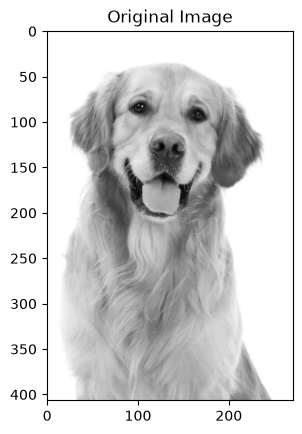

In [2]:
image = cv2.imread('image.png', cv2.IMREAD_GRAYSCALE)

plt.imshow(image, cmap="gray")
plt.title("Original Image")


Text(0.5, 1.0, 'Noisy Image (p=0.3)')

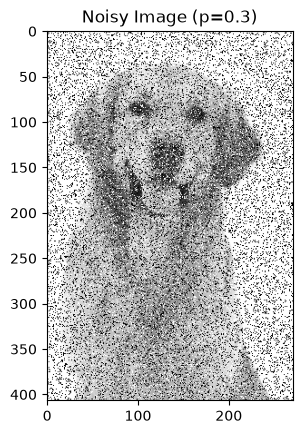

In [3]:
def add_salt_pepper_noise(image, probability=0.3, seed=None):
    """Randomly turn some pixels pure black (pepper) or pure white (salt)."""
    rng = np.random.default_rng(seed)
    noisy = image.copy()

    random_vals = rng.random(image.shape)   # one random number per pixel

    noisy[random_vals < probability / 2] = 0          # pepper (black)
    noisy[random_vals > 1 - probability / 2] = 255     # salt (white)
    return noisy

noisy = add_salt_pepper_noise(image, probability=0.3, seed=42)

plt.imshow(noisy, cmap="gray")
plt.title("Noisy Image (p=0.3)")


In [ ]:
def mirror_pad(image, pad):
    """Add a border by reflecting the image's own edge pixels outward."""
    return np.pad(image, pad_width=pad, mode='reflect')

In [ ]:
def extract_windows(image, kernel_size, stride):
    """Return every kernel_size x kernel_size neighborhood in the image."""
    pad = kernel_size // 2
    padded = mirror_pad(image, pad)

    # shape: (H, W, kernel_size, kernel_size) - one window per pixel
    windows = sliding_window_view(padded, (kernel_size, kernel_size))

    # keep only every `stride`-th window to shrink the output
    return windows[::stride, ::stride]

In [ ]:
def mean_filter(image, kernel_size=3, stride=1):
    """Replace each pixel with the average of its neighborhood."""
    windows = extract_windows(image, kernel_size, stride).astype(np.float32)
    return windows.mean(axis=(-1, -2)).astype(np.uint8)


def median_filter(image, kernel_size=3, stride=1):
    """Replace each pixel with the median of its neighborhood."""
    windows = extract_windows(image, kernel_size, stride)
    return np.median(windows, axis=(-1, -2)).astype(np.uint8)

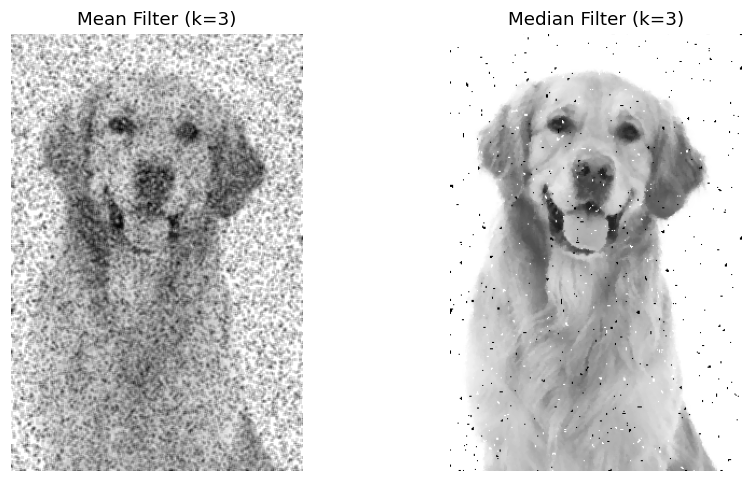

In [1]:
mean_result = mean_filter(noisy, kernel_size=3, stride=1)
median_result = median_filter(noisy, kernel_size=3, stride=1)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(mean_result, cmap="gray"); axes[0].set_title("Mean Filter (k=3)"); axes[0].axis("off")
axes[1].imshow(median_result, cmap="gray"); axes[1].set_title("Median Filter (k=3)"); axes[1].axis("off")
plt.tight_layout()

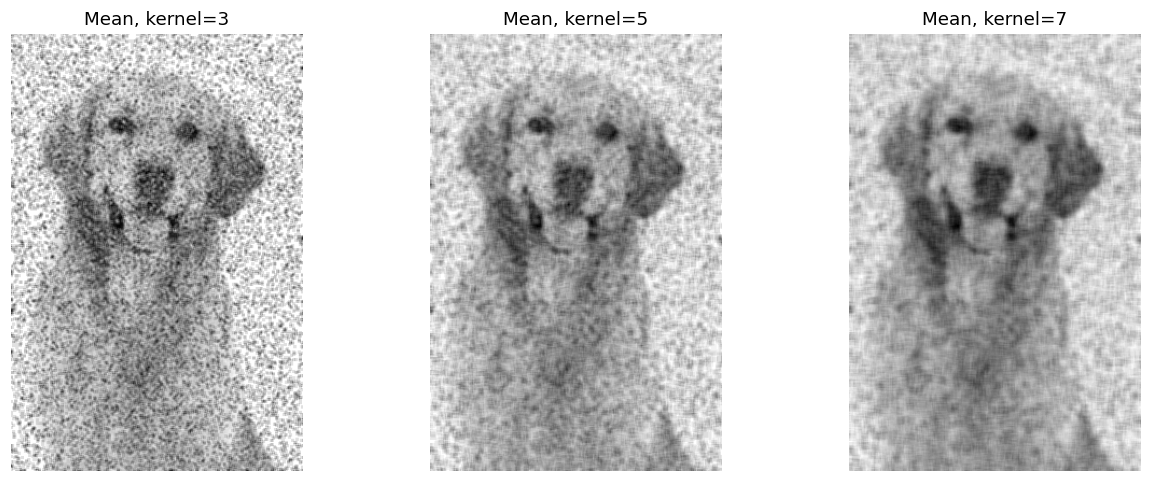

In [1]:
kernel_sizes = [3, 5, 7]
mean_by_k = [mean_filter(noisy, kernel_size=k, stride=1) for k in kernel_sizes]

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
for ax, k, r in zip(axes, kernel_sizes, mean_by_k):
    ax.imshow(r, cmap="gray"); ax.set_title(f"Mean, kernel={k}"); ax.axis("off")
plt.tight_layout()

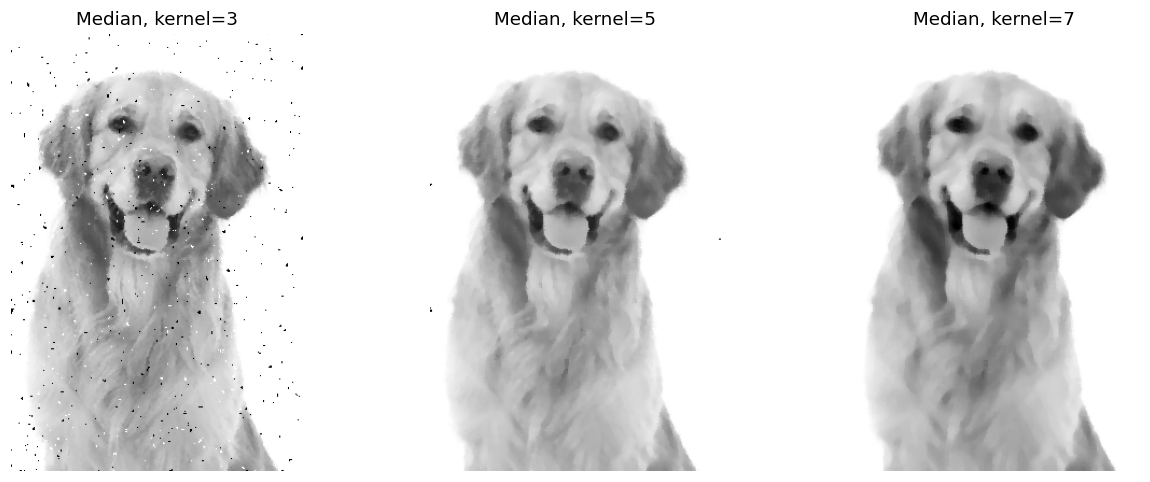

In [1]:
median_by_k = [median_filter(noisy, kernel_size=k, stride=1) for k in kernel_sizes]

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
for ax, k, r in zip(axes, kernel_sizes, median_by_k):
    ax.imshow(r, cmap="gray"); ax.set_title(f"Median, kernel={k}"); ax.axis("off")
plt.tight_layout()

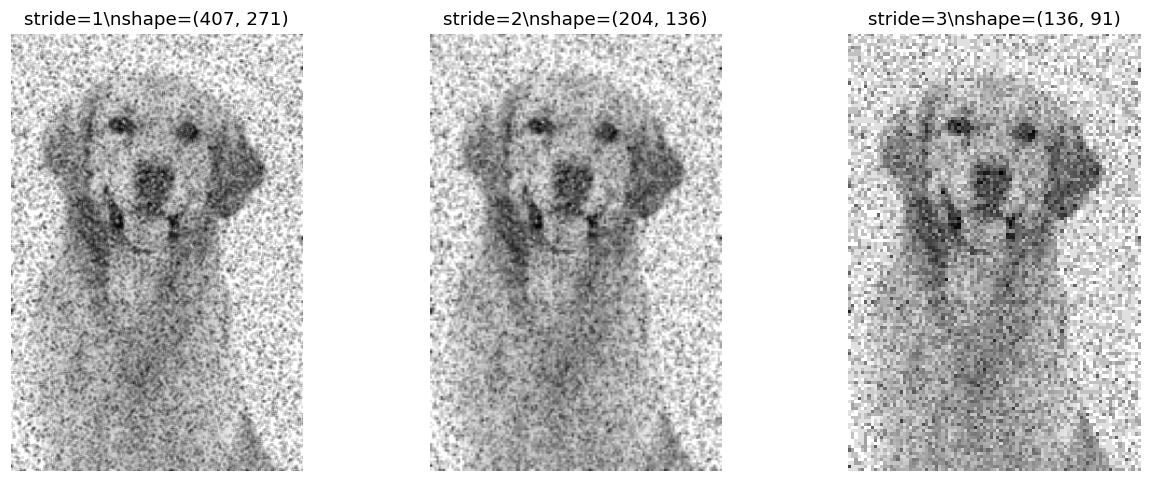

In [1]:
strides = [1, 2, 3]
mean_by_s = [mean_filter(noisy, kernel_size=3, stride=s) for s in strides]

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
for ax, s, r in zip(axes, strides, mean_by_s):
    ax.imshow(r, cmap="gray"); ax.set_title(f"stride={s}\nshape={r.shape}"); ax.axis("off")
plt.tight_layout()

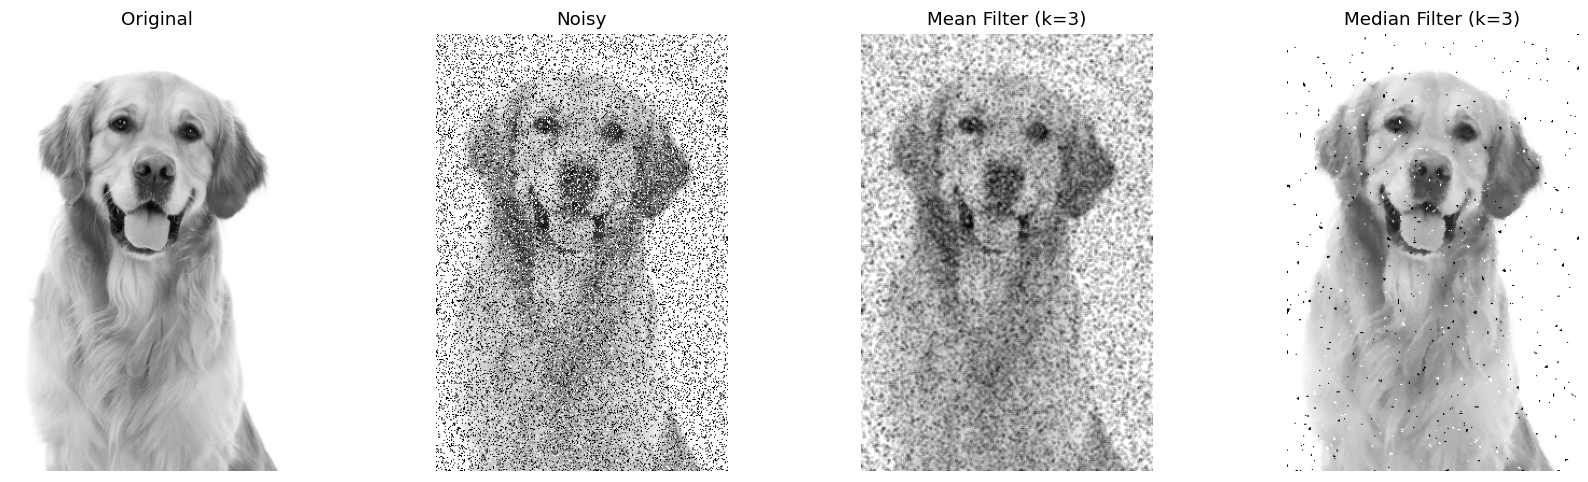

In [1]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, img, title in zip(
    axes,
    [image, noisy, mean_result, median_result],
    ["Original", "Noisy", "Mean Filter (k=3)", "Median Filter (k=3)"],
):
    ax.imshow(img, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout()